# Covariance

This notebook accompanies [Covariance](../../notes/joint_distributions_and_covariance/covariance.md). We compute covariance from its definition, compare with NumPy, check its algebraic properties, and see why zero covariance does not mean independence.

## Definition and shortcut formula

Using the paired data $X=(2,4,6,8)$ and $Y=(1,5,4,10)$, the sample covariance is $\frac1{n-1}\sum(X_i-\bar X)(Y_i-\bar Y)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

x = np.array([2.0, 4.0, 6.0, 8.0])
y = np.array([1.0, 5.0, 4.0, 10.0])
n = len(x)

dx, dy = x - x.mean(), y - y.mean()
print("Deviations X:", dx, " Y:", dy)
print("Products:", dx * dy, " sum =", (dx * dy).sum())

cov_def = (dx * dy).sum() / (n - 1)
cov_short = (np.sum(x * y) - n * x.mean() * y.mean()) / (n - 1)
print("Definition:", cov_def, " shortcut:", cov_short)
print("np.cov (n-1):", np.cov(x, y)[0, 1], " bias=True (n):", np.cov(x, y, bias=True)[0, 1])

Deviations X: [-3. -1.  1.  3.]  Y: [-4.  0. -1.  5.]
Products: [12. -0. -1. 15.]  sum = 26.0
Definition: 8.666666666666666  shortcut: 8.666666666666666
np.cov (n-1): 8.666666666666666  bias=True (n): 6.5


## Covariance matrix

`np.cov` returns the full matrix: variances on the diagonal and the covariance off the diagonal. Dividing by the standard deviations gives the correlation matrix.

In [2]:
S = np.cov(x, y)
print(S)
D = np.diag(1 / np.sqrt(np.diag(S)))
print("Correlation matrix:\n", D @ S @ D)
print("Matches np.corrcoef:", np.allclose(D @ S @ D, np.corrcoef(x, y)))

[[ 6.66666667  8.66666667]
 [ 8.66666667 14.        ]]
Correlation matrix:
 [[1.         0.89708523]
 [0.89708523 1.        ]]
Matches np.corrcoef: True


## Algebraic properties

Adding a constant leaves covariance unchanged; scaling multiplies it by the scale factors; and $\operatorname{Var}(aX+bY)=a^2\operatorname{Var}(X)+b^2\operatorname{Var}(Y)+2ab\operatorname{Cov}(X,Y)$.

In [3]:
cov = lambda a, b: np.cov(a, b)[0, 1]
print("Cov(X+100, Y)    =", cov(x + 100, y), "(unchanged:", cov(x, y), ")")
print("Cov(2X+1, 3Y-5)  =", cov(2 * x + 1, 3 * y - 5), " = 6*Cov =", 6 * cov(x, y))

a, b = 2.0, -3.0
lhs = np.var(a * x + b * y, ddof=1)
rhs = a**2 * np.var(x, ddof=1) + b**2 * np.var(y, ddof=1) + 2 * a * b * cov(x, y)
print("Var(2X-3Y):", lhs, "formula:", rhs)

Cov(X+100, Y)    = 8.666666666666666 (unchanged: 8.666666666666666 )
Cov(2X+1, 3Y-5)  = 52.0  = 6*Cov = 52.0
Var(2X-3Y): 48.666666666666664 formula: 48.66666666666666


## Covariance depends on units

Rescaling a variable (metres to centimetres) multiplies the covariance by the scale factor although the relationship is the same, which is why correlation is preferred as a measure of strength.

In [4]:
height_m = rng.normal(1.70, 0.08, 500)
weight_kg = 70 + 40 * (height_m - 1.70) + rng.normal(0, 5, 500)
print("Cov(m, kg)  =", round(cov(height_m, weight_kg), 4))
print("Cov(cm, kg) =", round(cov(100 * height_m, weight_kg), 4), "(100 times larger)")
print("Corr (m)    =", round(np.corrcoef(height_m, weight_kg)[0, 1], 4))
print("Corr (cm)   =", round(np.corrcoef(100 * height_m, weight_kg)[0, 1], 4))

Cov(m, kg)  = 0.2325
Cov(cm, kg) = 23.247 (100 times larger)
Corr (m)    = 0.511
Corr (cm)   = 0.511


## Zero covariance without independence

If $X$ is symmetric about $0$ and $Y=X^2$, then $\operatorname{Cov}(X,Y)=E[X^3]-E[X]E[X^2]=0$, yet $Y$ is a deterministic function of $X$.

Sample Cov(X, X^2): -0.0207
Sample Corr(X, X^2): -0.0141


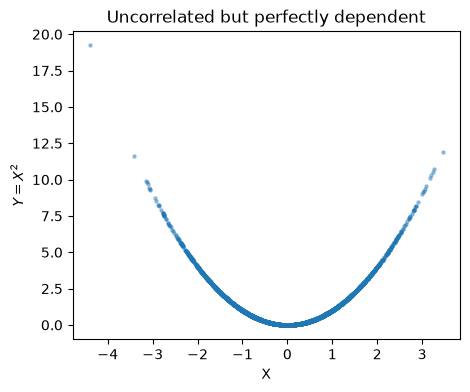

In [5]:
xs = rng.normal(0, 1, 5000)
ys = xs ** 2
print("Sample Cov(X, X^2):", round(cov(xs, ys), 4))
print("Sample Corr(X, X^2):", round(np.corrcoef(xs, ys)[0, 1], 4))

plt.figure(figsize=(5, 4))
plt.scatter(xs, ys, s=5, alpha=0.4)
plt.xlabel("X"); plt.ylabel("$Y = X^2$")
plt.title("Uncorrelated but perfectly dependent")
plt.show()